# Classification Metrics

This notebook computes the confusion matrix and derived metrics (accuracy, precision, recall, specificity, F1 and F-beta) both by hand and with scikit-learn, and explores multiclass averaging.

## Import Required Libraries

Import datasets, models and the metrics module.

In [1]:
# Import the required libraries.
import numpy as np
import matplotlib.pyplot as plt

from sklearn.datasets import load_breast_cancer, load_wine
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    confusion_matrix, accuracy_score, precision_score,
    recall_score, f1_score, fbeta_score, classification_report,
    ConfusionMatrixDisplay
)

# Define the course colour palette.
colors = ["#179E86", "#2580B7", "#9EBE5B",
          "#C03B26", "#44546A", "#F59B11"]
np.random.seed(42)

## Train a Binary Classifier

Fit logistic regression on the breast cancer data and obtain test predictions.

In [2]:
# Train a binary classifier and predict on the test set.
data = load_breast_cancer()
X, y = data.data, data.target
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42, stratify=y
)
model = LogisticRegression(max_iter=5000).fit(X_train, y_train)
y_pred = model.predict(X_test)

## The Confusion Matrix

Extract the four counts (TN, FP, FN, TP) that underlie every binary classification metric.

In [3]:
# Compute the binary confusion matrix.
cm = confusion_matrix(y_test, y_pred)
tn, fp, fn, tp = cm.ravel()
print(f"Confusion matrix:\n{cm}.")
print(f"TN={tn}, FP={fp}, FN={fn}, TP={tp}.")

Confusion matrix:
[[ 57   7]
 [  2 105]].
TN=57, FP=7, FN=2, TP=105.


## Metrics Computed by Hand

Derive accuracy, precision, recall, specificity, F1 and F-beta directly from the confusion-matrix counts.

In [4]:
# Compute the metrics by hand from the counts.
accuracy = (tp + tn) / (tp + tn + fp + fn)
precision = tp / (tp + fp)
recall = tp / (tp + fn)
specificity = tn / (tn + fp)
f1 = 2 * precision * recall / (precision + recall)
beta = 2
fbeta = ((1 + beta ** 2) * precision * recall /
         (beta ** 2 * precision + recall))

print(f"Accuracy:    {accuracy:.4f}.")
print(f"Precision:   {precision:.4f}.")
print(f"Recall:      {recall:.4f}.")
print(f"Specificity: {specificity:.4f}.")
print(f"F1:          {f1:.4f}.")
print(f"F-beta (2):  {fbeta:.4f}.")

Accuracy:    0.9474.
Precision:   0.9375.
Recall:      0.9813.
Specificity: 0.8906.
F1:          0.9589.
F-beta (2):  0.9722.


## The Same Metrics with scikit-learn

Confirm the hand calculations using the library functions.

In [5]:
# Compute the same metrics with scikit-learn.
print(f"Accuracy:   {accuracy_score(y_test, y_pred):.4f}.")
print(f"Precision:  {precision_score(y_test, y_pred):.4f}.")
print(f"Recall:     {recall_score(y_test, y_pred):.4f}.")
print(f"F1:         {f1_score(y_test, y_pred):.4f}.")
print("F-beta (2): "
      f"{fbeta_score(y_test, y_pred, beta=2):.4f}.")

Accuracy:   0.9474.
Precision:  0.9375.
Recall:     0.9813.
F1:         0.9589.
F-beta (2): 0.9722.


## Multiclass Problem and Averaging

Train a classifier on the wine dataset (three classes) to compare macro, micro and weighted averaging.

In [6]:
# Train a multiclass classifier on the wine dataset.
wine = load_wine()
Xw_tr, Xw_te, yw_tr, yw_te = train_test_split(
    wine.data, wine.target, test_size=0.3,
    random_state=42, stratify=wine.target
)
wine_model = LogisticRegression(max_iter=10000)
wine_model.fit(Xw_tr, yw_tr)
yw_pred = wine_model.predict(Xw_te)
print(f"Test classes: {np.bincount(yw_te)}.")

Test classes: [18 21 15].


## Macro vs Micro vs Weighted

Macro averages the per-class metric equally, micro aggregates the counts globally, and weighted weights by class support.

In [7]:
# Compare the three averaging strategies for F1.
for avg in ["macro", "micro", "weighted"]:
    score = f1_score(yw_te, yw_pred, average=avg)
    print(f"{avg:>8} F1: {score:.4f}.")

# Print the full per-class classification report.
print(classification_report(
    yw_te, yw_pred, target_names=wine.target_names
))

   macro F1: 0.9610.
   micro F1: 0.9630.
weighted F1: 0.9625.
              precision    recall  f1-score   support

     class_0       1.00      1.00      1.00        18
     class_1       0.91      1.00      0.95        21
     class_2       1.00      0.87      0.93        15

    accuracy                           0.96        54
   macro avg       0.97      0.96      0.96        54
weighted avg       0.97      0.96      0.96        54



## Confusion Matrix Heatmap

Display the multiclass confusion matrix as a labelled heatmap.

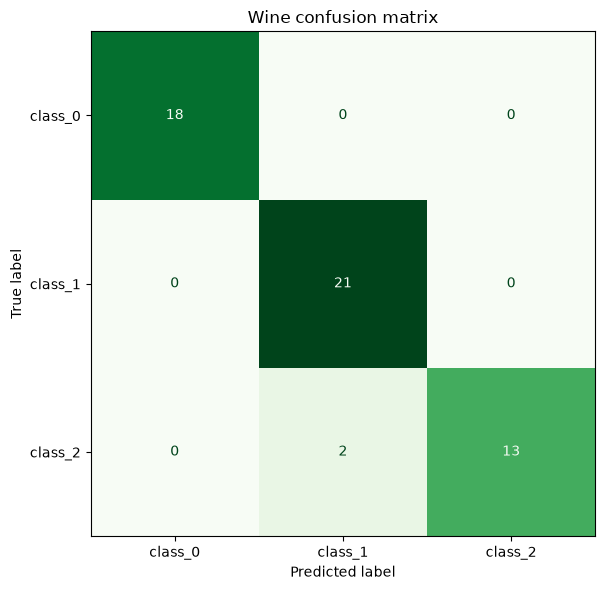

In [8]:
# Display the multiclass confusion matrix as a heatmap.
fig, ax = plt.subplots(figsize=(8, 6))
disp = ConfusionMatrixDisplay.from_predictions(
    yw_te, yw_pred, display_labels=wine.target_names,
    cmap="Greens", ax=ax, colorbar=False
)
ax.set_title("Wine confusion matrix")
plt.tight_layout()
plt.show()

## Summary

- **Confusion matrix**: the source of all classification metrics via the TN, FP, FN and TP counts.
- **Precision vs recall**: precision penalises false positives, recall penalises false negatives; F1 balances them.
- **F-beta**: beta > 1 weights recall more, beta < 1 weights precision more.
- **Averaging**: macro treats classes equally, micro favours frequent classes, and weighted scales by class support.